1. Concept of image sharpening
Image sharpening makes edges and fine details in an image more prominent.









1. Laplacian filter

Detects rapid changes in intensity using second-order derivatives. We combine the Laplacian response with the original image to enhance edges.












2. Sobel and Canny
- Sobel: Detects intensity changes in horizontal and vertical directions.
- Canny: Detects edges using smoothing, gradients, non-maximum suppression, and thresholding. Canny produces an edge map, not a sharpened image by itself, so we'll use its edges to enhance the original image.












3. Unsharp masking

First blur the image, then subtract the blurred image from the original to obtain a detail mask. Add this mask back to the original image to sharpen it.

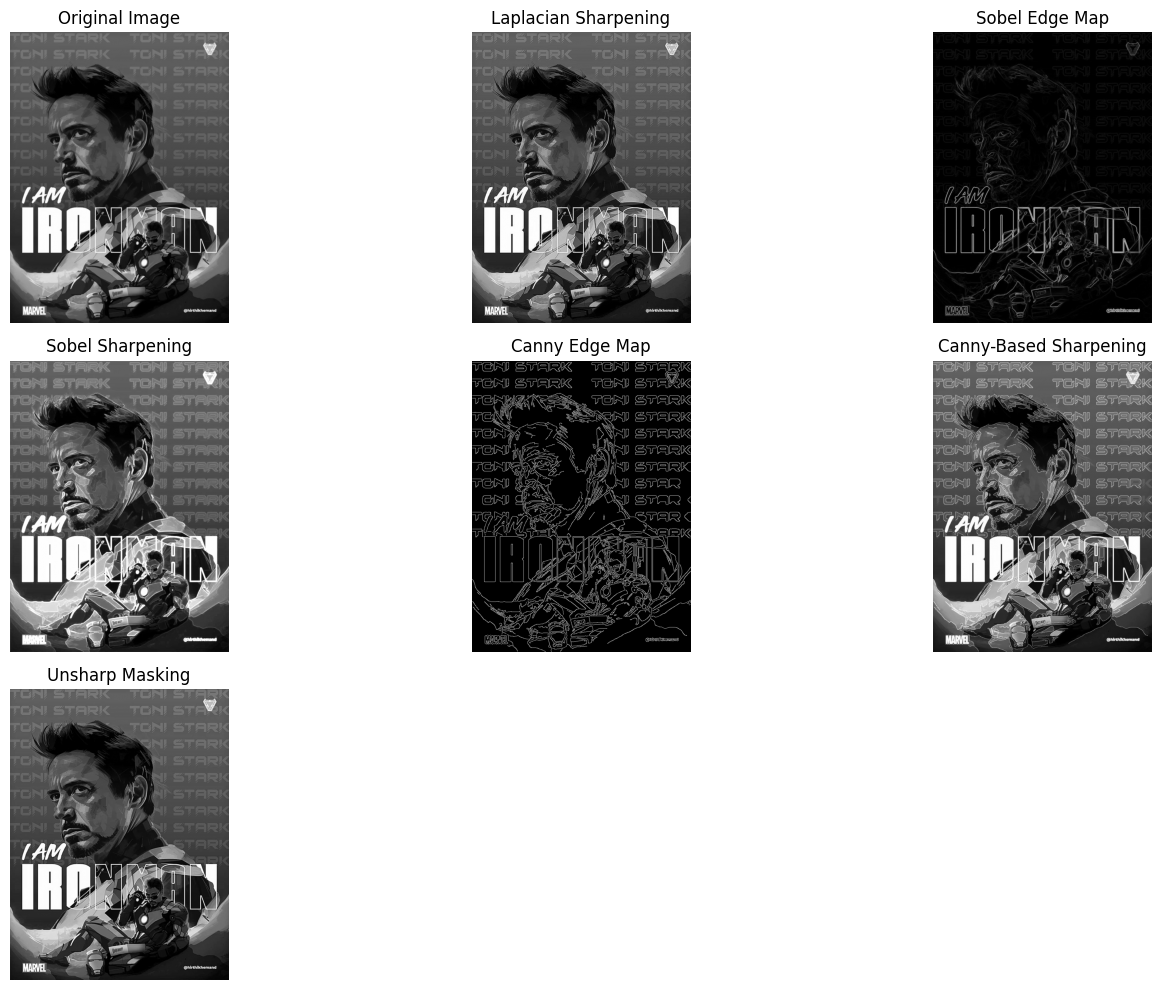

In [1]:
# Python code — without OpenCV
%pip install numpy pillow matplotlib scipy scikit-image
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from scipy.signal import convolve2d
from scipy.ndimage import gaussian_filter
from skimage.feature import canny

# Read grayscale image
img = np.array(
    Image.open("abc.jpg").convert("L"),
    dtype=np.float64
)

# 1. LAPLACIAN SHARPENING
laplacian_kernel = np.array([
    [0, -1,  0],
    [-1, 4, -1],
    [0, -1,  0]
], dtype=float)

laplacian = convolve2d(
    img, laplacian_kernel,
    mode="same", boundary="symm"
)

laplacian_sharp = np.clip(
    img + laplacian, 0, 255
).astype(np.uint8)


# 2. SOBEL SHARPENING
sobel_x = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
], dtype=float)

sobel_y = np.array([
    [-1, -2, -1],
    [ 0,  0,  0],
    [ 1,  2,  1]
], dtype=float)

gx = convolve2d(
    img, sobel_x, mode="same", boundary="symm"
)
gy = convolve2d(
    img, sobel_y, mode="same", boundary="symm"
)

gradient = np.sqrt(gx**2 + gy**2)

# Normalize gradient for display
sobel_edges = (
    gradient / (gradient.max() + 1e-8) * 255
).astype(np.uint8)

# Use gradient as a detail mask for sharpening
sobel_sharp = np.clip(
    img + 0.5 * gradient, 0, 255
).astype(np.uint8)


# CANNY EDGE DETECTOR
# Returns a binary edge map
canny_edges = canny(
    img / 255.0,
    sigma=1.0,
    low_threshold=0.1,
    high_threshold=0.2
)

canny_edges = (canny_edges * 255).astype(np.uint8)

# Enhance the original using Canny edges
canny_sharp = np.clip(
    img + 0.5 * canny_edges, 0, 255
).astype(np.uint8)


# 3. UNSHARP MASKING
# Required Gaussian blur: size 5x5, sigma = 3
# A 5x5 Gaussian kernel is constructed manually.
coords = np.arange(-2, 3)
X, Y = np.meshgrid(coords, coords)

sigma = 3.0

gaussian_kernel = np.exp(
    -(X**2 + Y**2) / (2 * sigma**2)
)
gaussian_kernel /= gaussian_kernel.sum()

blurred = convolve2d(
    img, gaussian_kernel,
    mode="same", boundary="symm"
)

mask = img - blurred

unsharp = np.clip(
    img + mask, 0, 255
).astype(np.uint8)


# DISPLAY RESULTS
images = [
    (img, "Original Image"),
    (laplacian_sharp, "Laplacian Sharpening"),
    (sobel_edges, "Sobel Edge Map"),
    (sobel_sharp, "Sobel Sharpening"),
    (canny_edges, "Canny Edge Map"),
    (canny_sharp, "Canny-Based Sharpening"),
    (unsharp, "Unsharp Masking")
]

plt.figure(figsize=(14, 10))

for i, (image, title) in enumerate(images, 1):
    plt.subplot(3, 3, i)
    plt.imshow(image, cmap="gray", vmin=0, vmax=255)
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

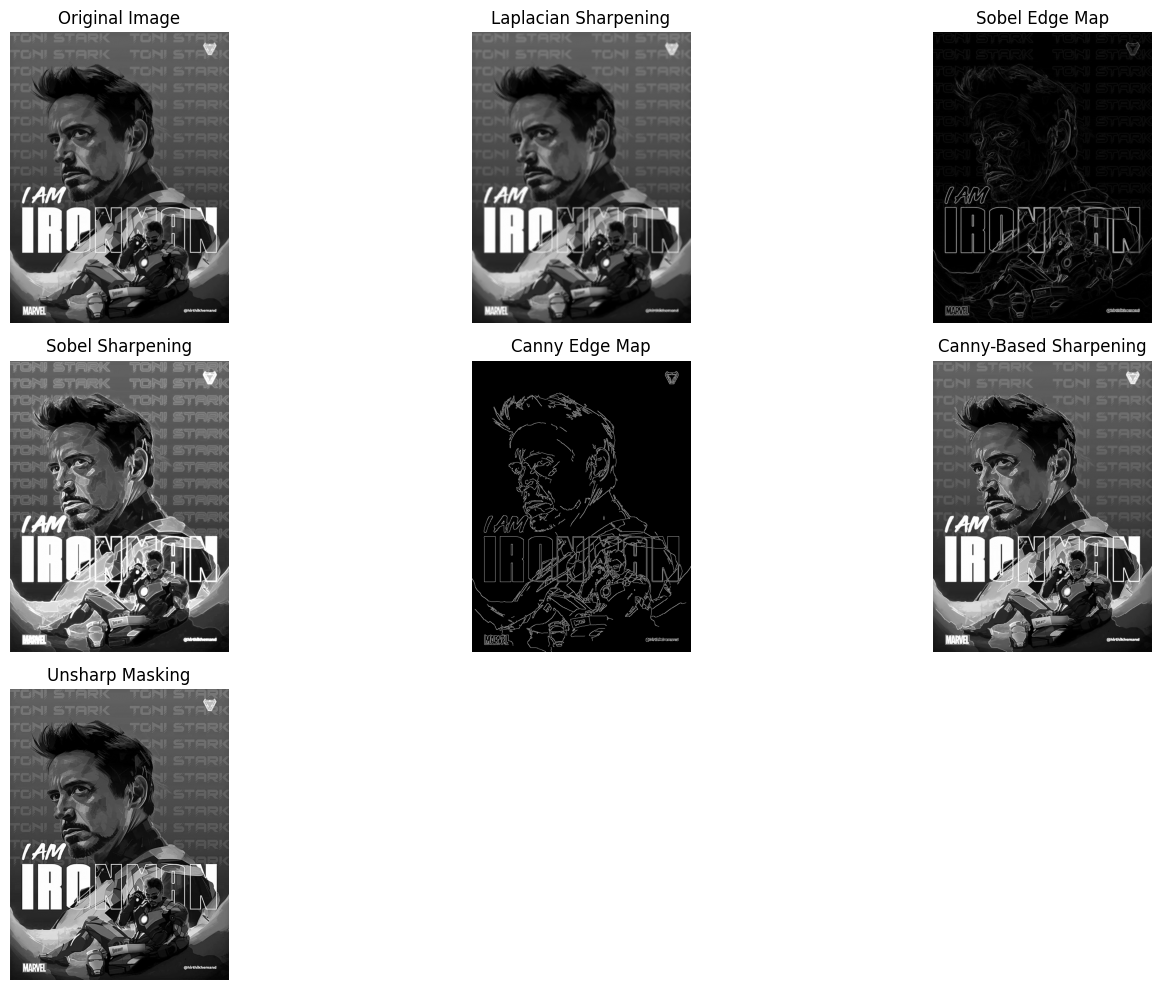

In [2]:
# OpenCV code

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read grayscale image
img = cv2.imread("abc.jpg", cv2.IMREAD_GRAYSCALE)

if img is None:
    raise FileNotFoundError("Check the image path.")

# Convert to float for sharpening calculations
img_float = img.astype(np.float32)


# 1. LAPLACIAN SHARPENING
laplacian = cv2.Laplacian(
    img_float, cv2.CV_32F, ksize=1
)

laplacian_sharp = np.clip(
    img_float + laplacian, 0, 255
).astype(np.uint8)


# 2. SOBEL SHARPENING
gx = cv2.Sobel(
    img_float, cv2.CV_32F, 1, 0, ksize=3
)
gy = cv2.Sobel(
    img_float, cv2.CV_32F, 0, 1, ksize=3
)

gradient = cv2.magnitude(gx, gy)

sobel_edges = cv2.normalize(
    gradient, None, 0, 255,
    cv2.NORM_MINMAX
).astype(np.uint8)

sobel_sharp = np.clip(
    img_float + 0.5 * gradient, 0, 255
).astype(np.uint8)


# CANNY EDGE DETECTION
canny_edges = cv2.Canny(
    img, threshold1=100, threshold2=200
)

# Use detected edges to enhance the original
canny_sharp = np.clip(
    img_float + 0.5 * canny_edges.astype(np.float32),
    0, 255
).astype(np.uint8)


# 3. UNSHARP MASKING
# Required kernel size = 5x5 and sigma = 3
blurred = cv2.GaussianBlur(
    img, (5, 5), sigmaX=3, sigmaY=3
)

mask = img_float - blurred.astype(np.float32)

unsharp = np.clip(
    img_float + mask, 0, 255
).astype(np.uint8)


# DISPLAY ALL RESULTS
images = [
    (img, "Original Image"),
    (laplacian_sharp, "Laplacian Sharpening"),
    (sobel_edges, "Sobel Edge Map"),
    (sobel_sharp, "Sobel Sharpening"),
    (canny_edges, "Canny Edge Map"),
    (canny_sharp, "Canny-Based Sharpening"),
    (unsharp, "Unsharp Masking")
]

plt.figure(figsize=(14, 10))

for i, (image, title) in enumerate(images, 1):
    plt.subplot(3, 3, i)
    plt.imshow(image, cmap="gray", vmin=0, vmax=255)
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()